# Plotting and visualization

This tutorial sketches practical ways to visualize an `xsnowDataset`. The emphasis is on workflows that are useful during analysis: first inspect profiles interactively, then build custom plots from the underlying data.



## Viewing profiles interactively

Interactive profile viewers are the most convenient starting point when you want to inspect snow stratigraphy, scroll through time, switch locations or aspects, and quickly compare parameters.


### nivix

[nivix](https://gitlab.com/avalanche-warning/visualization/nivix) is an external community project for browser-based visualization of snow stratigraphy, snow-cover time series, ensembles, profile views, and selected instability indices. It provides a Python backend named `xserver` that can register an `xsnowDataset.show()` method. A live demo is linked from the nivix repository. 

To learn more about the project including ways to employ it, check the [nivix wiki](https://gitlab.com/avalanche-warning/visualization/nivix/-/wikis/home) and explore the info button inside the nivix interface top-right corner.

![nivix screenshot](../resources/nivix_screenshot.png)


```{admonition} Installing nivix
:class: note

To install install nivix and the xserver backend, simply install xsnow with visualization extras:

`pip install xsnow[viz]`

```

```
import xsnow
import xserver  # registers the show method
xs = xsnow.sample_data.snp_gridded_ds()
xs.show()  # opens nivix in local browser
```

```{warning}
The xsnow project and the nivix project currently cannot provide support for interface issues between xsnow and nivix. The workflow above has been tested successfully on Linux machines. Windows and macOS remain untested at this time. If the local browser workflow does not work on your system, use one of the fallback options below.
```


#### Ensemble and distribution views

nivix is not limited to a single deterministic snow-cover run. It also includes ensemble and distribution visualizations that make it possible to compare multiple realizations, inspect spread, and identify outlying members. Check the live demo linked from the nivix repository to see these views in action.

Within xsnow, nivix uses the `realization` dimension for this ensemble-style exploration. If your dataset already stores model members, scenarios, or forecast perturbations along `realization`, you can explore them directly in nivix.

If you want to compare another axis in the same way, for example multiple locations, you can create a temporary viewer dataset where that axis is packed into `realization`. This does not change your original dataset; it only reshapes a shallow copy for visualization---each `(location, realization)` pair is shown as one nivix realization:

```python
import xsnow
import xserver

xs = xsnow.sample_data.snp_gridded_ds()
xs_viewer = xs.copy()

# Treat each location-realization pair as one realization for visualization.
xs_viewer = xs_viewer.stack(viewer_realization=("location", "realization"))
viewer_labels = [
    f"{location} | {realization}"
    for location, realization in xs_viewer["viewer_realization"].to_index()
]

# Drop the temporary MultiIndex levels before renaming the temporary axis.
xs_viewer = xs_viewer.reset_index("viewer_realization", drop=True)
xs_viewer = xs_viewer.rename({"viewer_realization": "realization"})
xs_viewer = xs_viewer.assign_coords(realization=viewer_labels)

xs_viewer.show(realization="distribution")
```

The same pattern can be adapted for other dimensions, as long as the result still represents data that nivix can interpret as alternative realizations of comparable profiles.

![nivix screenshot on distribution](../resources/nivix_screenshot_distribution.png)


### Fallback: season plot extension

xsnow also ships a lightweight Plotly-based season plot extension. It is useful for quick inspection of one location/aspect time series.

See the API docs for {doc}`xsnow.extensions.season_plot <../api/_generated/xsnow.extensions.season_plot>` for more information.


In [ ]:
import xsnow
import xsnow.extensions.season_plot

xs = xsnow.single_profile_timeseries()
fig = xs.plot_season(["grain_type", "density", "temperature"])
fig.show()

[i] xsnow.io: Parsing 2 datasets eagerly with 13 workers...
[i] xsnow.utils: Slope coordinate 'inclination' varies by location. Preserving (location, slope) dimensions as allow_per_location=True.
[i] xsnow.utils: Slope coordinate 'azimuth' varies by location. Preserving (location, slope) dimensions as allow_per_location=True.


```{important}
The season plot extension displays irregular snow layers on a regular plotting surface. It regrids the layer dimension onto a regular height axis with piecewise-constant layer fills. That makes the plot relatively fast, but it can hide very thin layers or show a vertical reference that differs from the exact native layer geometry. Check the extension documentation and inspect the underlying data when exact layer geometry matters.
```


### Fallback: niViz and other PRO/SMET tools

[niviz.org](https://niviz.org/) can load SNOWPACK `.pro` and `.smet` files directly in the browser. xsnow can export compatible files, so this is a useful route when the local nivix workflow is unavailable.


Any other plotting or inspection tool that understands standard snow-cover model data formats should be accessible through the same intermediate export route.


## Custom plots

For custom figures, treat `xs.data` as an ordinary `xarray.Dataset`. Use xarray to select, reduce, and align the data; then pass small tabular outputs to `matplotlib`, `pandas`, `folium`, or any other plotting library.


In [ ]:
import xsnow

xs = xsnow.sample_data.snp_gridded_ds().compute()

[i] xsnow.io: Computing 25 delayed datasets with 13 workers...


<xsnowDataset>
  Locations:  5
  Timestamps: 416 (2024-01-16--2024-02-02)
  Profiles:   10400 total | 10400 valid | 8861 with HS>0

    employing the <xarray.Dataset> Size: 47MB
    Dimensions:                   (location: 5, time: 416, slope: 5,
                                   realization: 1, layer: 36)
    Coordinates:
      * location                  (location) <U5 100B 'VIR1A' 'VIR2A' ... 'VIR5A'
        altitude                  (location) float64 40B 2.372e+03 ... 2.066e+03
        latitude                  (location) float64 40B 47.15 47.44 ... 47.44 47.37
        longitude                 (location) float64 40B 11.19 11.29 11.3 11.39 11.5
      * time                      (time) datetime64[us] 3kB 2024-01-16T05:00:00 ....
      * slope                     (slope) int64 40B 0 1 2 3 4
        azimuth                   (slope) float64 40B 0.0 0.0 90.0 180.0 270.0
        inclination               (slope) float64 40B 0.0 38.0 38.0 38.0 38.0
      * realization               (realization) int64 8B 0
      * layer                     (layer) int64 288B 0 1 2 3 4 5 ... 31 32 33 34 35
        z                         (location, time, slope, realization, layer) float32 1MB ...
    Data variables: (12/92)
        ColdContentSnow           (location, time, slope, realization) float64 83kB ...
        DW                        (location, time, slope, realization) float64 83kB ...
        HN12                      (location, time, slope, realization) float64 83kB ...
        HN24                      (location, time, slope, realization) float64 83kB ...
        HN3                       (location, time, slope, realization) float64 83kB ...
        HN6                       (location, time, slope, realization) float64 83kB ...
        ...                        ...
        zS4                       (location, time, slope, realization) float64 83kB ...
        zS5                       (location, time, slope, realization) float64 83kB ...
        zSd                       (location, time, slope, realization) float64 83kB ...
        zSn                       (location, time, slope, realization) float64 83kB ...
        zSs                       (location, time, slope, realization) float64 83kB ...
        HS                        (location, time, slope, realization) float32 42kB ...
    Attributes:
        Conventions:  CF-1.8
        crs:          EPSG:4326

### Scatterplot with marginal distributions

The next example compares snow height (`HS`) and 24-hour new snow (`HN24`) at the latest timestep. Points are colored by station altitude. The code deliberately keeps the data preparation separate from the plotting calls so that each step is easy to adapt.


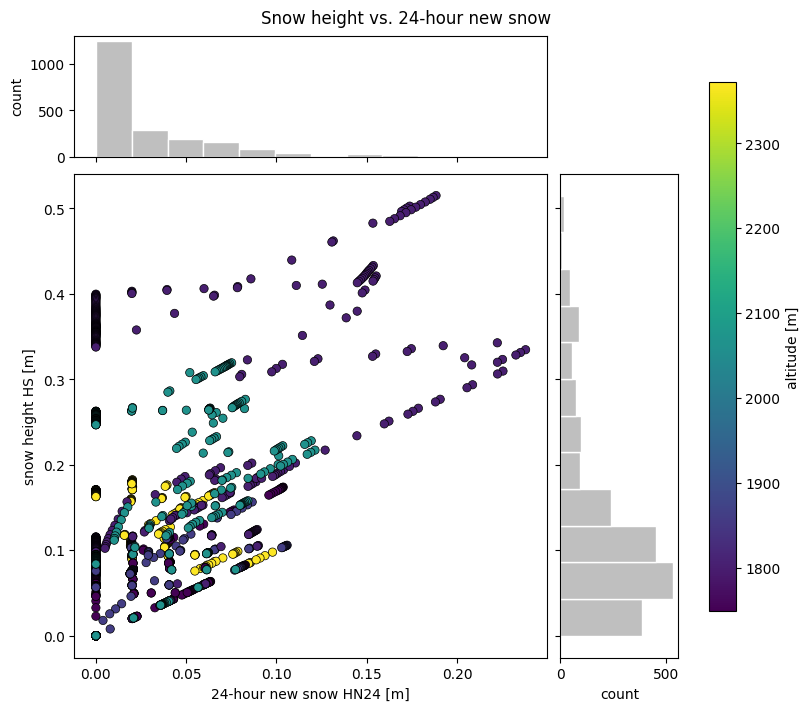

In [10]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Pick one slope/realization/time
# Adjust these selections for your own dataset.
selected = xs.isel(slope=0, realization=0)

plot_data = selected[["HS", "HN24"]].to_dataframe().reset_index()
plot_data["altitude"] = selected["altitude"].to_pandas().reindex(plot_data["location"]).values
plot_data = plot_data.dropna(subset=["HS", "HN24", "altitude"])

fig = plt.figure(figsize=(8, 7), constrained_layout=True)
gs = GridSpec(2, 2, figure=fig, width_ratios=(4, 1), height_ratios=(1, 4))

ax_hist_x = fig.add_subplot(gs[0, 0])
ax_scatter = fig.add_subplot(gs[1, 0], sharex=ax_hist_x)
ax_hist_y = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

scatter = ax_scatter.scatter(
    plot_data["HN24"],
    plot_data["HS"],
    c=plot_data["altitude"],
    cmap="viridis",
    edgecolor="black",
    linewidth=0.5,
)

ax_hist_x.hist(plot_data["HN24"], bins=12, color="0.75", edgecolor="white")
ax_hist_y.hist(plot_data["HS"], bins=12, orientation="horizontal", color="0.75", edgecolor="white")

ax_scatter.set_xlabel("24-hour new snow HN24 [m]")
ax_scatter.set_ylabel("snow height HS [m]")
ax_hist_x.set_ylabel("count")
ax_hist_y.set_xlabel("count")

ax_hist_x.tick_params(labelbottom=False)
ax_hist_y.tick_params(labelleft=False)

cbar = fig.colorbar(scatter, ax=[ax_scatter, ax_hist_x, ax_hist_y], shrink=0.85)
cbar.set_label("altitude [m]")

fig.suptitle("Snow height vs. 24-hour new snow")
plt.show()


### Interactive map with background tiles

For a map with terrain context, `folium` can draw colored symbols on web map tiles. This requires internet access when the notebook is rendered or viewed because the tile server is contacted by the browser. This example colors each location by the latest snow height.


In [16]:
import folium
import matplotlib as mpl
from branca.colormap import LinearColormap

selected = xs.isel(time=-1, slope=0, realization=0)
map_data = selected[["HS"]].to_dataframe().reset_index()
map_data["latitude"] = selected["latitude"].to_pandas().reindex(map_data["location"]).values
map_data["longitude"] = selected["longitude"].to_pandas().reindex(map_data["location"]).values
map_data = map_data.dropna(subset=["HS", "latitude", "longitude"])

center = [map_data["latitude"].mean(), map_data["longitude"].mean()]
m = folium.Map(location=center, zoom_start=10, tiles="OpenTopoMap")

norm = mpl.colors.Normalize(vmin=map_data["HS"].min(), vmax=map_data["HS"].max())
cmap = mpl.colormaps["Blues"]

colorbar = LinearColormap(
    colors=[mpl.colors.to_hex(cmap(value)) for value in (0.2, 0.45, 0.7, 0.95)],
    vmin=float(map_data["HS"].min()),
    vmax=float(map_data["HS"].max()),
    caption="Snow height HS [m]",
)

for row in map_data.itertuples():
    color = mpl.colors.to_hex(cmap(norm(row.HS)))
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=10,
        color="black",
        weight=1,
        fill=True,
        fill_color=color,
        fill_opacity=0.85,
        tooltip=f"{row.location}: HS={row.HS:.2f} m",
    ).add_to(m)

colorbar.add_to(m)
m


## Share your plotting extensions

If you create plots that may be useful for other community members, consider sharing them as custom xsnow extensions. Visualization needs differ strongly between workflows, so xsnow's visualization ecosystem has an opportunity to grow through contributions!
